### **PARTE 1 - CARGA Y EXPLORACIÓN DE DATOS**

##### Importación de librerías

In [1]:
# Instalar xlrd si no está instalado
!pip install xlrd -q

# Tratamiento de Datos
import pandas as pd
import numpy as np

#Gráficos
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import sklearn
import matplotlib.pyplot as plt
from matplotlib import style

#Preprocesamiento y Modelo

from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, RepeatedKFold
from sklearn.model_selection import cross_val_score, cross_validate, cross_val_predict
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.linear_model import ElasticNetCV

# Configurar estilo de gráficos
plt.style.use('ggplot')

# Preprocesado y análisis
from scipy import stats

# Configurar advertencias
import warnings
warnings.filterwarnings('ignore')



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


##### 1. Cargar del dataset proporcionado

In [128]:
# Cargar archivo csv
df = pd.read_csv(r"C:\Users\dashi\OneDrive\Escritorio\Cursos\Machine Learning\Proyecto_Machine_Learning\construccion_datos.csv")
 

##### 2. Visualizar los primeros registros del conjunto de datos

In [129]:
df.head(10)

,id_proyecto,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,nivel_acabados,tipo_terreno,complejidad_diseno,acceso_obra,costo_construccion_crc
0,OBRA-0001,163.6,4,2.0,1,Básico,Plano,Baja,Fácil,33237000
1,OBRA-0002,281.3,4,2.0,1,Estándar,Plano,Baja,Fácil,90560000
2,OBRA-0003,285.1,6,3.0,1,Premium,Plano,Media,Intermedio,119998000
3,OBRA-0004,259.6,6,4.0,2,Básico,Plano,Media,Difícil,75370000
4,OBRA-0005,246.8,5,2.0,1,Estándar,Plano,Media,Fácil,88955000
5,OBRA-0006,178.7,3,1.0,2,Estándar,Plano,Baja,Fácil,57618000
6,OBRA-0007,111.6,3,2.0,2,Estándar,Plano,Media,Fácil,30989000
7,OBRA-0008,240.1,4,1.0,2,Premium,Plano,Media,Fácil,101866000
8,OBRA-0009,NaN,3,2.0,2,Estándar,Plano,Alta,Fácil,55663000
9,OBRA-0010,165.3,3,1.0,1,Premium,Plano,Media,Intermedio,69182000


##### 3. Identificar las dimensiones del dataset

In [130]:
print("Dimensiones del dataset:", df.shape)

Dimensiones del dataset: (600, 10)


##### 4. Verificar valores faltantes, registros duplicados y los tipos de datos

In [131]:
# Valores faltantes por columna
print("Valores faltantes por columna:")
print(df.isnull().sum())

#Registros duplicados
print("\nCantidad de registros duplicados:", df.duplicated().sum())

#Tipos de datos
print("\nTipos de datos:")
print(df.dtypes)

Valores faltantes por columna:
id_proyecto                0
area_construida_m2        15
numero_habitaciones        0
numero_banos              18
numero_pisos               0
nivel_acabados             0
tipo_terreno              15
complejidad_diseno         0
acceso_obra               12
costo_construccion_crc     0
dtype: int64

Cantidad de registros duplicados: 0

Tipos de datos:
id_proyecto                   str
area_construida_m2        float64
numero_habitaciones         int64
numero_banos              float64
numero_pisos                int64
nivel_acabados                str
tipo_terreno                  str
complejidad_diseno            str
acceso_obra                   str
costo_construccion_crc      int64
dtype: object


##### 5. Obtener estadísticas descriptivas de las variables numéricas y revisar las categorías existentes

In [132]:
df.describe().round(2)

,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,costo_construccion_crc
count,585.00,600.00,582.00,600.00,6.000000e+02
mean,174.18,3.44,1.98,1.44,6.416956e+07
std,65.14,1.47,0.91,0.62,2.705788e+07
min,70.40,1.00,1.00,1.00,2.300000e+07
25%,115.70,2.00,1.00,1.00,4.198225e+07
50%,170.30,3.00,2.00,1.00,6.099450e+07
75%,233.50,5.00,3.00,2.00,8.204450e+07
max,289.00,6.00,5.00,3.00,1.570910e+08


##### Interpretación de la Estadística Descriptiva

1. Las viviendas tienen un área construida entre **70,4 m²** y **289,0 m²**, con un promedio aproximado de **174,18 m²**. 
2. La mediana es de **170,3 m²**, por lo que la distribución del área se concentra alrededor de ese valor. 
3. El número de habitaciones varía entre 1 y 6, mientras que los baños van de 1 a 5. Además, los proyectos tienen entre 1 y 3 pisos. 
4. El costo de construcción varía entre **₡23.000.000** y **₡157.091.000**, con un costo promedio cercano a ₡64.169.560. Esta es la variable que se buscará estimar mediana los modelos de regresión. 

In [133]:
# Selecionar las columnas categóricas, excluyendo el identificador

columnas_categoricas = [
    "nivel_acabados",
    "tipo_terreno",
    "complejidad_diseno",
    "acceso_obra"
]

for columna in columnas_categoricas:
    print(f"\nCategorías de {columna}:")
    print(df[columna].unique())


Categorías de nivel_acabados:
<StringArray>
['Básico', 'Estándar', 'Premium']
Length: 3, dtype: str

Categorías de tipo_terreno:
<StringArray>
['Plano', 'Pendiente moderada', nan, 'Pendiente pronunciada']
Length: 4, dtype: str

Categorías de complejidad_diseno:
<StringArray>
['Baja', 'Media', 'Alta']
Length: 3, dtype: str

Categorías de acceso_obra:
<StringArray>
['Fácil', 'Intermedio', 'Difícil', nan]
Length: 4, dtype: str


##### 6. Identificar cuál es la variable dependiente y cuáles son las variables independientes.

In [134]:
# Variable dependiente
y = df["costo_construccion_crc"]

# Variables independientes
x = df.drop(columns=["id_proyecto", "costo_construccion_crc"])

print("Variable dependiente:")
print(y.name)

print("\nVariable independiente:")
print(x.columns.tolist())

Variable dependiente:
costo_construccion_crc

Variable independiente:
['area_construida_m2', 'numero_habitaciones', 'numero_banos', 'numero_pisos', 'nivel_acabados', 'tipo_terreno', 'complejidad_diseno', 'acceso_obra']


##### 7. Explicación del por qué el identificador del proyecto no debe utilizarse como variable predictora

La variable `id_proyecto` no debe utilizarse como variable predictora porque es únicamente un identificador único asignado a cada proyecto. Los valores como OBRA-0001 u OBRA-0002, no representan una característica física, técnica o económica de la vivienda. Por tanto, incluirla podría llevar al modelo a aprender patrones artificiales relacionados con el orden de registro de los proyectos, en lugar de aprender la relación real entre las características de una vivienda y su costo de construcción. Por esta razón, debe excluirse antes de entrenar los modelos. 

##### **Pregunta de análisis: ¿Qué información contiene el dataset y qué característica de los proyectos estamos intentando predecir?**

El dataset contiene información sintética de **600 proyectos de viviendas residenciales**. Incluye una identificación del proyecto, características físicas (área, habitaciones, baños y pisos) y características técnicas (nivel de acabados, tipo de terreno, complejidad del diseño y acceso a la obra). Esta información nos permite confirmar que la característica que se busca predecir es el costo total estimado de construcción de una nueva vivienda en colones costarricenses. 

### **PARTE 2 - ANÁLISIS EXPLORATORIO Y RELACIONES ENTRE VARIABLES**

##### 1. Construir un histograma que represente la distribución de los costos de construcción

In [135]:
#Formula de Sturges

import math

def sturges_formula(n):
  k = 1 +3.32 * math.log10(n)
  return round(k)

n = 600 # reemplazar con la cantidad de filas del set de datos
num_bins = sturges_formula(n)
print('Numero de bines segun la formula de Sturges es: ', num_bins)

Numero de bines segun la formula de Sturges es:  10


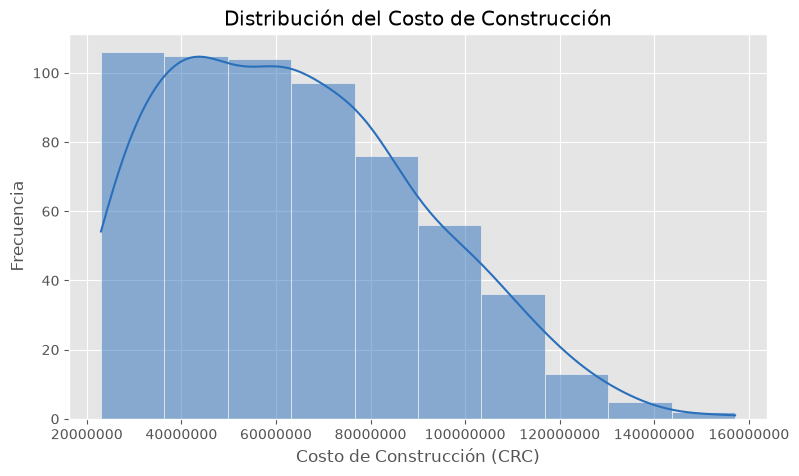

In [136]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df, 
    x="costo_construccion_crc",
    bins=10,
    kde=True,
    color="#2a6fbb"
)

plt.title("Distribución del Costo de Construcción")
plt.xlabel("Costo de Construcción (CRC)")
plt.ylabel("Frecuencia")
plt.ticklabel_format(style="plain",axis="x")
plt.show()

##### 2. Elaborar un gráfico de dispersión entre el área construida y el costo total del proyecto

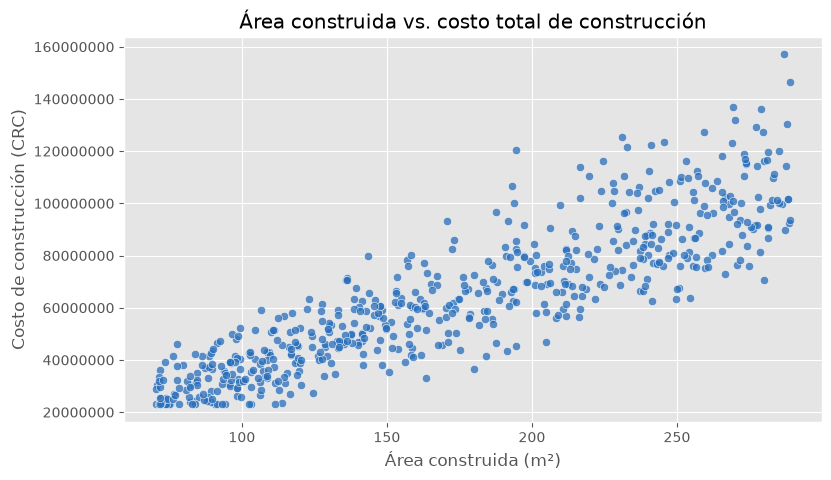

In [137]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="area_construida_m2",
    y="costo_construccion_crc",
    alpha=0.75,
    color="#2a6fbb" 
)

plt.title("Área construida vs. costo total de construcción")
plt.xlabel("Área construida (m²)")
plt.ylabel("Costo de construcción (CRC)")
plt.ticklabel_format(style="plain",axis="y")
plt.show()

##### 3. Construir un diagrama de cajas para comparar los costos según el nivel de acabados

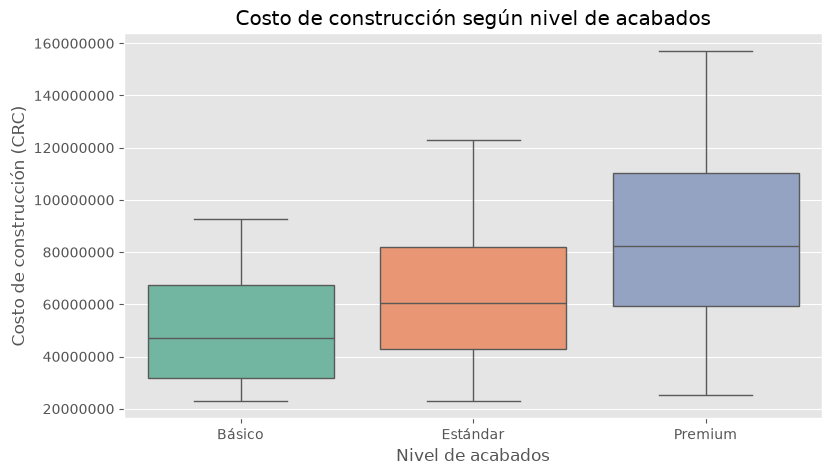

In [138]:
orden_acabados = ["Básico", "Estándar", "Premium"]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="nivel_acabados",
    y="costo_construccion_crc",
    order=orden_acabados, 
    hue="nivel_acabados",
    palette="Set2",
    legend=False
)

plt.title("Costo de construcción según nivel de acabados")
plt.xlabel("Nivel de acabados")
plt.ylabel("Costo de construcción (CRC)")
plt.ticklabel_format(style="plain",axis="y")
plt.show()

##### 4. Calcular una matriz de correlación utilizando las variables numéricas

In [139]:
# Seleccionar las columnas numéricas 
variables_numericas = df.select_dtypes(include="number")

#calcular la matriz de correlación
matriz_correlacion = variables_numericas.corr(method='pearson')

#Mostrar la matriz
display(matriz_correlacion.round(3))

,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,costo_construccion_crc
area_construida_m2,1.000,0.848,0.631,0.047,0.883
numero_habitaciones,0.848,1.000,0.759,0.031,0.751
numero_banos,0.631,0.759,1.000,-0.055,0.572
numero_pisos,0.047,0.031,-0.055,1.000,0.062
costo_construccion_crc,0.883,0.751,0.572,0.062,1.000


##### 5. Representar gráficamente las correlaciones mediante un mapa de calor

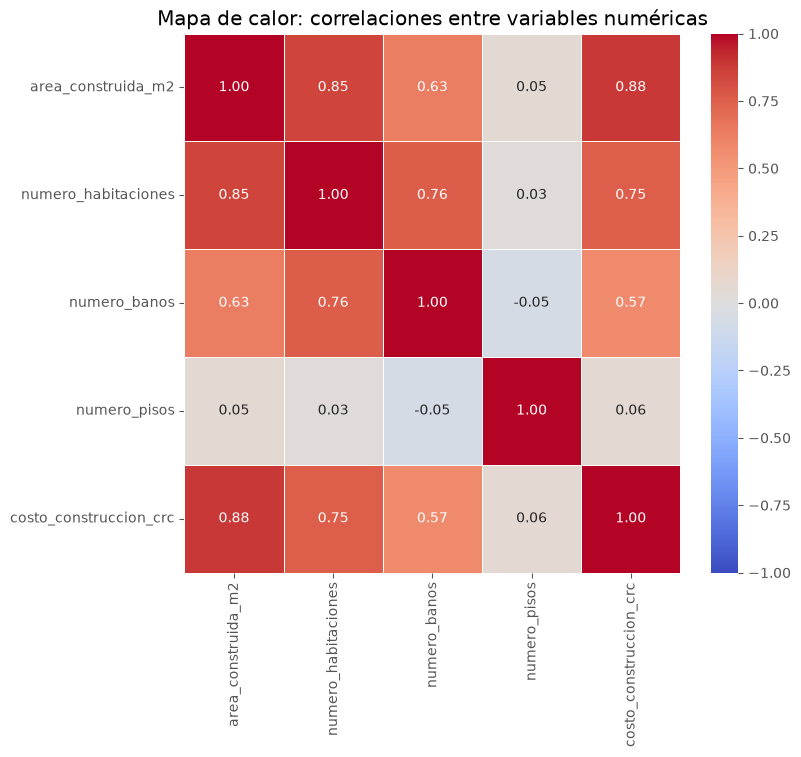

In [140]:
plt.figure(figsize=(8, 7))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)

plt.title("Mapa de calor: correlaciones entre variables numéricas")
plt.show()

##### 6. Identificar al menos dos hallazgos relevantes sobre las relaciones observadas

1. El `área construida` es la variable númerica más relacionada con el `costo de construcción`, con una correlación positiva de **0,883**, lo que confirma que las viviendas de mayor tamaño tienden a requerir más materiales y mano de obra, por lo que su costo total suele aumentar. 
2. El nivel de acabados diferencia los costos de los proyectos. La mediana de los costos aumenta desde aproximadamente **₡46.977.000** en acabados Básicos, a **₡60.383.000** en Estándar y **₡82.465.000** en Premium. 
3. El número de habitaciones y baños también se relaciona positivamente con el costo. Sus correlaciones con la variable objetivo son 0,751 y 0,572 respectivamente. 

##### **Pregunta de análisis: ¿Cuáles características parecen tener una mayor relación con los costos de construcción? ¿Por qué una correlación no necesariamente implica causalidad?**

Las características que parecen tener mayor relación con los costos de construcción son:

1. Área construida, por su relación lineal fuerte con el costo. 
2. Número de habitaciones. 
2. Número de baños porque está asociado con instalaciones, materiales y mano de obra adicionales. 
3. Nivel de acabados, ya que los acabados Premium muestran costos superiores a los niveles Básico y Estándar. 

Por otro lado, una correlación no implica causalidad porque una relación estadística entre dos variables no demuestra, por sí misma, que una variable sea la causa directa de la otra. Por ejemplo, el número de habitaciones puede estar correlacionado con el costo porque las viviendas más grandes suelen incluir más habitaciones; en este caso, el área construida puede ser un factor subyacente que influye en ambas variables. 

### **PARTE 3 - PREPARACIÓN DE DATOS Y CONSTRUCCIÓN DE MODELOS**

##### 1. División de datos

In [141]:
# Division de los datos
#20% EN EL TEST 
#80% EN EL TRAIN 

X = df.drop(columns = ['id_proyecto', 'costo_construccion_crc'])
y = df['costo_construccion_crc']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y.values.reshape(-1,1),
    test_size = 0.2,
    random_state = 42,
    shuffle = True)

print(f'Observaciones totales: {len(df)}')
print(f'Entrenamiento: {X_train.shape[0]} observaciones ({X_train.shape[0] / len(df):.0%})')
print(f'Prueba: {X_test.shape[0]} observaciones ({X_test.shape[0] / len(df):.0%})')

Observaciones totales: 600
Entrenamiento: 480 observaciones (80%)
Prueba: 120 observaciones (20%)


##### 2. Preprocesamiento de datos

Para cumplir el requisito de evitar fugas de información (data leakage), todos los parámetros del preprocesamiento (medianas, modas y categorías del One-Hot Encoding) deben calcularse únicamente sobre el conjunto de entrenamiento y posteriormente aplicarse tanto al conjunto de entrenamiento como al de prueba

In [142]:
# Pipeline de preprocesamiento

variables_numericas = X_train.select_dtypes(include=['number']).columns.tolist()

variables_categoricas = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Pipeline para variables numéricas: imputar valores faltantes con la mediana de X_train
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

#Pipeline para variables categóricas: imputar con la moda y aplicar One-Hot Encoding
categoricas_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

#Combinar ambos preprocesamientos
preprocesamiento = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, variables_numericas),
    ('cat', categoricas_transformer, variables_categoricas)
])

preprocesamiento

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_na

In [143]:
# Ajustar el preprocesamiento SOLO con el conjunto de entrenamiento
X_train_prep = preprocesamiento.fit_transform(X_train)

#Ajustar la misma transformación al conjunto de prueba
X_test_prep = preprocesamiento.transform(X_test)

print('Dimensión entrenamiento:', X_train_prep.shape)
print('Dimensión prueba:', X_test_prep.shape)

Dimensión entrenamiento: (480, 16)
Dimensión prueba: (120, 16)


##### 3. Entrenamiento de Modelos

OLS

In [144]:
#Crear el modelo de regresión lineal (OLS)
modelo_lineal = LinearRegression()

#Entrenar exclusivamente con los datos de entrenamiento 
modelo_lineal.fit(X_train_prep, y_train)

#Confirmar el entrenamiento
print("Modelo entrenado con éxito:", type(modelo_lineal).__name__)
print("Proyectos utilizados para entrenamiento:", X_train.shape[0])
print("Variables de entrada después del preprocesamiento:",modelo_lineal.n_features_in_)

Modelo entrenado con éxito: LinearRegression
Proyectos utilizados para entrenamiento: 480
Variables de entrada después del preprocesamiento: 16


KNN

In [145]:
# Crear y entrenar el modelo KNN con 7 vecinos
modelo_knn = KNeighborsRegressor(n_neighbors=7)
modelo_knn.fit(X_train_prep, y_train)

# Confirmar el entrenamiento
print("Modelo KNN entrenado con éxito:", type(modelo_knn).__name__)
print("Número de vecinos:", modelo_knn.n_neighbors)
print("Proyectos utilizados para entreamiento:", X_train.shape[0])
print("Variables de entrada después del preprocesamiento:",modelo_knn.n_features_in_)
print("Dimensiones de X_test procesado:", X_test_prep.shape)

Modelo KNN entrenado con éxito: KNeighborsRegressor
Número de vecinos: 7
Proyectos utilizados para entreamiento: 480
Variables de entrada después del preprocesamiento: 16
Dimensiones de X_test procesado: (120, 16)


Random Forest Regressor

In [146]:
# Crear el modelo Random Forest 
modelo_random_forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,random_state=42)

# Entrenar el modelo con el conjunto de entrenamiento
modelo_random_forest.fit(X_train_prep, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [147]:
# Confirmar la configuración y el entrenamiento 
print("Modelo Random Forest entrenado con éxito:", type(modelo_random_forest).__name__)
print("Número de árboles:", modelo_random_forest.n_estimators)
print("Mínimo de muestras por hoja:", modelo_random_forest.min_samples_leaf)
print("Semilla aleatoria:",modelo_random_forest.random_state)
print("Proyectos utilizados para entrenamiento:", X_train.shape[0])
print("Variables de entrada después del preprocesamiento:", modelo_random_forest.n_features_in_)
print("Dimensiones de X_test procesado:", X_test_prep.shape)

Modelo Random Forest entrenado con éxito: RandomForestRegressor
Número de árboles: 200
Mínimo de muestras por hoja: 2
Semilla aleatoria: 42
Proyectos utilizados para entrenamiento: 480
Variables de entrada después del preprocesamiento: 16
Dimensiones de X_test procesado: (120, 16)


##### **Pregunta de análisis: ¿Por qué el escalamiento de las variables resulta importante para KNN? ¿Qué diferencias existen entre el funcionamiento de estos 3 algoritmos?**

El escalamiento de las variables es importante para KNN porque este algoritmo calcula la similitud entre proyectos mediante distancias. Si las variables numéricas conservan sus escalas originales, una variable con valores más amplios, como area_construida_m2, puede influir más en la distancia que variables con rangos menores, como el número de pisos o de baños. Por esta razón se utilizó StandardScaler(), ya que transforma las variables numéricas para que tengan una escala comparable. De esta forma, cada característica aporta de manera más equilibrada al cálculo de los 7 vecinos más cercanos.

Las diferencias principales entre los tres algoritmos son:

1. **Regresión Lineal (OLS)**: ajusta una ecuación lineal global que relaciona las características del proyecto con el costo de construcción. Estima coeficientes para cada variable y busca minimizar el error cuadrático entre los costos reales y predichos.
2. **K-Nearest Neighbors (KNN)**: no construye una ecuación. Para estimar el costo de una vivienda, identifica los 7 proyectos más similares en el conjunto de entrenamiento y utiliza el promedio de sus costos. Su desempeño depende de la medida de distancia y, por ello, requiere escalamiento.
3. **Random Forest**: construye múltiples árboles de decisión y promedia sus predicciones. Puede capturar relaciones no lineales e interacciones entre características, por ejemplo, combinaciones entre área construida, nivel de acabados y tipo de terreno. No requiere escalamiento, ya que sus divisiones se basan en valores umbral de las variables y no en distancias.

### **PARTE 4 - EVALUACIÓN Y COMPARACIÓN DE MODELOS**

##### 1. Predicciones sobre los datos de prueba 

In [148]:
prediccion_lineal = modelo_lineal.predict(X= X_test_prep)
prediccion_lineal = prediccion_lineal.flatten()
prediccion_lineal[:10]

array([6.04084487e+07, 3.62842564e+07, 4.93477003e+07, 1.08967180e+08,
       6.10694251e+07, 9.52111404e+07, 6.82408457e+07, 9.60690032e+07,
       5.39959400e+07, 1.44330690e+07])

In [149]:
prediccion_knn = modelo_knn.predict(X = X_test_prep)
prediccion_knn = prediccion_knn.flatten()
prediccion_knn[:10]

array([46941285.71428572, 46110000.        , 38501000.        ,
       90647571.42857143, 55747285.71428572, 92576285.71428572,
       69337714.28571428, 97242000.        , 61809428.57142857,
       25168000.        ])

In [150]:
prediccion_forest = modelo_random_forest.predict(X = X_test_prep)
prediccion_forest = prediccion_forest.flatten()
prediccion_forest[:10]

array([56339017.83333334, 44562196.82142857, 28375856.67857143,
       97617294.05555554, 56506543.50595236, 93731875.5       ,
       69464188.22510825, 88657071.43055555, 48441806.32936509,
       24617250.55555555])

##### 2. Calcular el error absoluto (MAE)

Cuanto menor sea el MAE, mejor será el modelo, ya que significa que las predicciones están más cerca de los valores reales. 

In [151]:
mae_lineal = mean_absolute_error(y_test, prediccion_lineal)
mae_knn = mean_absolute_error(y_test, prediccion_knn)
mae_forest = mean_absolute_error(y_test, prediccion_forest)

print(f"MAE del modelo de regresión lineal: ₡{mae_lineal:,.2f}")
print(f"MAE del modelo KNN: ₡{mae_knn:,.2f}")
print(f"MAE del modelo Random Forest: ₡{mae_forest:,.2f}")

MAE del modelo de regresión lineal: ₡5,763,249.02
MAE del modelo KNN: ₡10,500,284.52
MAE del modelo Random Forest: ₡6,521,165.40


##### 3. Calcular la raíz del error cuadrático medio (RMSE)

El RMSE mide el tamaño promedio de los errores de predicción, penalizando más fuertemente los errores grandes debido a que las diferencias se elevan al cuadrado de promediarse. Por consiguiente, cuanto menor sea el RMSE, mejor será la capacidad predictiva del modelo.

In [152]:
mse_lineal = mean_squared_error(y_true = y_test, y_pred = prediccion_lineal)
mse_knn = mean_squared_error(y_true = y_test, y_pred = prediccion_knn)
mse_forest = mean_squared_error(y_true = y_test, y_pred = prediccion_forest)

rmse_lineal = np.sqrt(mse_lineal)
rmse_knn = np.sqrt(mse_knn)
rmse_forest = np.sqrt(mse_forest)

print(f'El error (rmse) del test OLS es: ₡{rmse_lineal:,.2f}')
print(f'El error (rmse) del test KNN es: ₡{rmse_knn:,.2f}')
print(f'El error (rmse) del test Random Forest es: ₡{rmse_forest:,.2f}')

El error (rmse) del test OLS es: ₡7,839,797.10
El error (rmse) del test KNN es: ₡14,111,595.84
El error (rmse) del test Random Forest es: ₡8,190,679.54


##### 4. Calcular el coeficiente de determinación (R2)

Mide qué proporción de la variabilidad de la variable objetivo es explicada por el modelo. Por tanto, mientras más cercano a 1, mejor será el ajuste del modelo. 

In [153]:
r2_ols = r2_score( y_true  = y_test, y_pred = prediccion_lineal)
r2_knn = r2_score( y_true  = y_test, y_pred = prediccion_knn)
r2_forest = r2_score( y_true  = y_test, y_pred = prediccion_forest)

print(f'El coeficiente determinacion del test OLS es: {r2_ols}')
print(f'El coeficiente determinacion del test KNN es: {r2_knn}')
print(f'El coeficiente determinacion del test Random Forest es: {r2_forest}')

El coeficiente determinacion del test OLS es: 0.9252231343137709
El coeficiente determinacion del test KNN es: 0.7577242924239371
El coeficiente determinacion del test Random Forest es: 0.9183798328792354


##### 5. Tabla comparativa con los resultados obtenidos

,Modelo,RMSE,R²
0,OLS,7.839797e+06,0.925
1,KNN,1.411160e+07,0.758
2,Random Forest,8.190680e+06,0.918


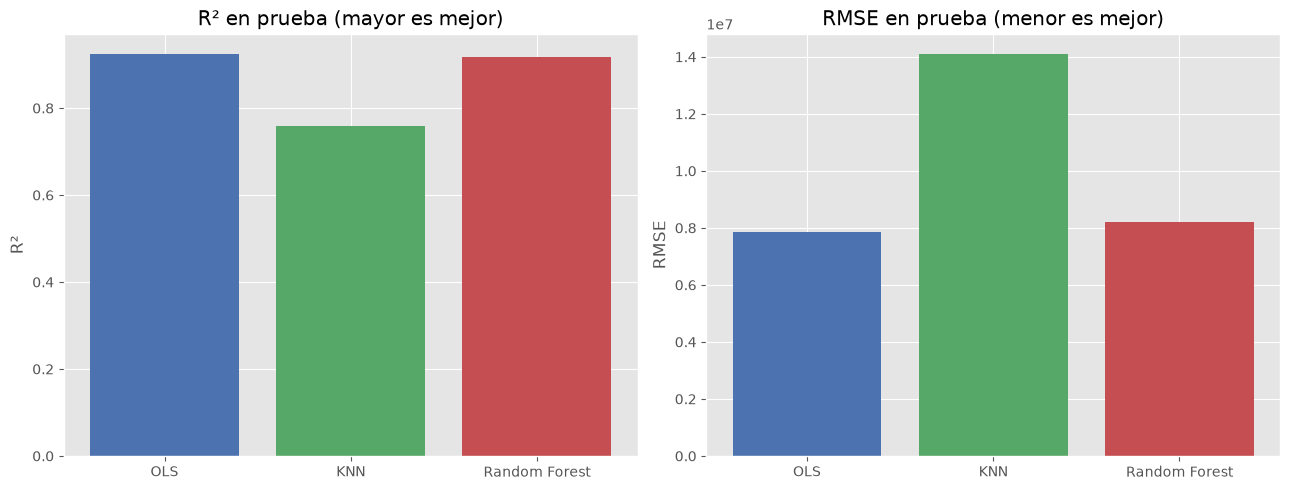

In [165]:
resultados_modelos = pd.DataFrame({
    'Modelo': ['OLS', 'KNN', 'Random Forest'],
    'RMSE': [rmse_lineal, rmse_knn, rmse_forest],
    'R²': [r2_ols, r2_knn, r2_forest]
})

resultados_modelos

display(resultados_modelos.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colores = ['#4c72b0', '#55a868', '#c44e52']

axes[0].bar(resultados_modelos['Modelo'], resultados_modelos['R²'], color=colores)
axes[0].set_title('R² en prueba (mayor es mejor)')
axes[0].set_ylabel('R²')

axes[1].bar(resultados_modelos['Modelo'], resultados_modelos['RMSE'], color=colores)
axes[1].set_title('RMSE en prueba (menor es mejor)')
axes[1].set_ylabel('RMSE')

plt.tight_layout()
plt.show()

##### 6. Identificación del modelo que presenta mejor RMSE y explicar su selección

El modelo seleccionado es la Regresión Lineal, ya que obtuvo el menor RMSE ₡7.839.797,10. Se selecciona porque el RMSE penaliza con mayor fuerza los errores grandes. Por tanto, el menor RMSE indica que, entre los tres modelos evaluados, la Regresión Lineal produce las predicciones de costo con menor magnitud de error cuadrático en el conjunto de prueba para estimar los costos de construcción de viviendas residenciales.  

##### 7. Aplicación del modelo seleccionado a nuevos datos

In [155]:
# Cargar nuevas datos
nuevos_proyectos = pd.read_csv(r"C:\Users\dashi\OneDrive\Escritorio\Cursos\Machine Learning\Proyecto_Machine_Learning\construccion_nuevas_obras.csv")
nuevos_proyectos.head(10)

,id_proyecto,area_construida_m2,numero_habitaciones,numero_banos,numero_pisos,nivel_acabados,tipo_terreno,complejidad_diseno,acceso_obra
0,NUEVO-01,85,2,1,1,Básico,Plano,Baja,Fácil
1,NUEVO-02,110,3,2,1,Estándar,Plano,Media,Fácil
2,NUEVO-03,130,3,2,2,Estándar,Pendiente moderada,Media,Intermedio
3,NUEVO-04,155,4,3,2,Premium,Plano,Alta,Fácil
4,NUEVO-05,180,4,3,2,Estándar,Pendiente pronunciada,Alta,Difícil
5,NUEVO-06,205,5,3,2,Premium,Pendiente moderada,Alta,Intermedio
6,NUEVO-07,90,2,1,1,Básico,Pendiente pronunciada,Baja,Intermedio
7,NUEVO-08,125,3,2,1,Premium,Plano,Media,Fácil
8,NUEVO-09,245,5,4,2,Estándar,Plano,Alta,Difícil
9,NUEVO-10,275,6,4,3,Premium,Pendiente pronunciada,Alta,Difícil


In [156]:
# Separar el identificador

X_nuevos = nuevos_proyectos.drop(columns=['id_proyecto'])

# Aplicar el mismo preprocesamiento ajustado con entrenamiento

X_nuevos_prep = preprocesamiento.transform(X_nuevos)

In [157]:
# Generar predicciones con el modelo de regresión lineal (OLS)

predicciones_nuevas = modelo_lineal.predict(X_nuevos_prep)

print(predicciones_nuevas)

[[1.35987429e+07]
 [3.93258043e+07]
 [5.26701345e+07]
 [8.01980692e+07]
 [8.78943475e+07]
 [1.03412363e+08]
 [2.90676042e+07]
 [6.14641877e+07]
 [9.86139661e+07]
 [1.38997531e+08]
 [4.98193268e+07]
 [7.09940073e+07]]


In [158]:
# Tabla con el identificador del proyecto y el costo estimado
tabla_predicciones = pd.DataFrame({ 
    "id_proyecto": nuevos_proyectos["id_proyecto"], 
    "costo_estimado_crc": predicciones_nuevas.flatten().round().astype(int)
}) 

tabla_predicciones["costo_estimado_crc"] = ( 
    tabla_predicciones["costo_estimado_crc"] 
    .apply(lambda x: f"₡{x:,}") 
) 

tabla_predicciones

,id_proyecto,costo_estimado_crc
0,NUEVO-01,"₡13,598,743"
1,NUEVO-02,"₡39,325,804"
2,NUEVO-03,"₡52,670,135"
3,NUEVO-04,"₡80,198,069"
4,NUEVO-05,"₡87,894,348"
5,NUEVO-06,"₡103,412,363"
6,NUEVO-07,"₡29,067,604"
7,NUEVO-08,"₡61,464,188"
8,NUEVO-09,"₡98,613,966"
9,NUEVO-10,"₡138,997,531"


##### **Pregunta de análisis: ¿Qué implicaciones tendría para una empresa constructora que su modelo presente un error promedio de varios millones de colones?**

1. Subestimación del costo: podría generar presupuestos insuficientes, reducción de márgenes de ganancia, necesidad de recursos adicionales o desviaciones presupuestarias durante la ejecución.
2. Sobreestimación del costo: podría producir cotizaciones poco competitivas y reducir la posibilidad de obtener contractos de proyectos.
3. Planificación financiera: las estimaciones deben utilizarse como apoyo en etapas iniciales, considerando márgenes de contingencia antes de establecer presupuestos definitivos para la asignación de recursos, la compra de materiales y la contratación de personal. 
4. Toma de decisiones: el modelo puede agilizar la evaluación preliminar de proyectos, pero debe complementarse con revisión técnica, precios actualizados de materiales, condiciones específicas del terreno y costos de mano de obra.

### **PARTE 5 - CONCLUSIONES EMPRESARIALES**

#### 1 - ¿Cuál de los tres modelos obtuvo el mejor resultado y por qué?

El modelo que obtuvo el mejor resultado fue la Regresión Lineal. Esto se debe a que presentó los mejores valores en las métricas evaluadas, obteniendo el menor error promedio (MAE), el menor RMSE y el mayor valor de R². En otras palabras, fue el modelo que logró realizar las predicciones más cercanas a los costos reales de construcción, mostrando un desempeño superior al de KNN y Random Forest para este conjunto de datos.

#### 2- ¿Qué significa el valor de R² obtenido por el mejor modelo? 

El valor de `R² fue approx 0.93`, lo que significa que el modelo explica cerca del  *93% de la variabilidad* de los costos de construcción a partir de las características de las viviendas incluidas en el análisis. Esto indica que existe una relación fuerte entre las variables utilizadas y el costo final, por lo que el modelo tiene una buena capacidad de realizar estimaciones preliminares. 

#### 3- ¿Qué características de las viviendas parecen estar más relacionadas con el costo de construcción?

Las características que mostraron una mayor relación con el costo fueron principalmente el área construida, el número de habitaciones, el número de baños y el nivel de acabados. Esto tiene sentido porque las viviendas más grandes requieren más materiales y mano de obra, mientras que los acabados de mayor calidad suelen incrementar significativamente el costo total del proyecto. 

#### 4- ¿Qué limitaciones tendría utilizar estos modelos para elaborar presupuestos de construcción reales?

Aunque los resultados obtenidos fueron buenos, estos modelos tienen algunas limitaciones. Por ejemplo, no consideran factores que pueden influir en proyectos reales, como cambios en los precios de materiales, variaciones en los costos de mano de obra, condiciones económicas, ubicación específica del proyecto o situaciones imprevistas durante la construcción. Además, el modelo presenta un margen de error, por lo que las predicciones deben utilizarse como una referencia inicial y no como un presupuesto definitivo.

#### 5- ¿Considera que este tipo de modelos podría resultar útil para apoyar el proceso de presupuestación de una empresa constructora? Justifique su respuesta.
Sí, considero que este tipo de modelos puede ser una herramienta muy útil para una empresa constructora. Permiten obtener estimaciones rápidas de costos a partir de información básica del proyecto, lo que facilita la planificación inicial y la toma de decisiones. Además, pueden ayudar a reducir el tiempo dedicado al análisis manual y servir como apoyo para identificar proyectos que requieren una evaluación más detallada. Sin embargo, sus resultados deben complementarse con la experiencia de los profesionales y con un análisis técnico antes de elaborar un presupuesto final.